John S. Anvik, 2025  
University of Lethbridge Student ID: 001224816

Import Packages

In [30]:
# install.packages("tidymodels")
# install.packages('rlang')
# install.packages("kknn")
library(tidyverse)
library(tidymodels)

# set random seed
set.seed(42)

Load data

In [31]:
data <- read_csv("../data/matching_opportunities.csv") %>%
    drop_na() # drop any row containing at least one NA value

Rows: 709 Columns: 22
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
dbl  (21): D_M1_M2, D_M1_M3, D_M1_M4, D_M1_M5, D_M1_M6, UST, M1_last_UST, M2...
dttm  (1): DateTime

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [32]:
# Model Inputs
model_columns <- c(
        # "UST", 
        "does_it_match",
        "D_M1_M2", "D_M1_M3", "D_M1_M4", "D_M1_M5", "D_M1_M6",
        "M1_last_UST", "M2_last_UST", "M3_last_UST", "M4_last_UST", "M5_last_UST", "M6_last_UST", # TODO: These are categorical variables, how does this implementation of knn handle those?
        # "time_M1_last_song", "time_M2_last_song", "time_M3_last_song", "time_M4_last_song", "time_M5_last_song", "time_M6_last_song",
    	"time_since_M1_last_song", "time_since_M2_last_song", "time_since_M3_last_song", "time_since_M4_last_song", "time_since_M5_last_song", "time_since_M6_last_song" # did not include time since M1 last song because it is always 0
        # "time_rel_sunrise"
    )

In [33]:
# Set data types and select input columns
data <- data %>% 
    mutate(across(contains("UST"), ~ as.factor(.x)), 
        does_it_match = as.factor(does_it_match),
        number_of_matches = as.integer(number_of_matches)) %>%
    select(model_columns)

In [34]:
glimpse(data)

Rows: 416
Columns: 18
$ does_it_match           <fct> 1, 0, 1, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0, 1…
$ D_M1_M2                 <dbl> 94.0368, 94.0368, 94.0368, 94.0368, 94.0368, 9…
$ D_M1_M3                 <dbl> 53.50176, 46.47336, 46.47336, 46.47336, 46.473…
$ D_M1_M4                 <dbl> 61.21936, 61.21936, 61.21936, 61.21936, 61.219…
$ D_M1_M5                 <dbl> 62.95599, 62.95599, 62.95599, 62.95599, 62.955…
$ D_M1_M6                 <dbl> 78.21623, 62.38124, 62.38124, 62.38124, 62.381…
$ M1_last_UST             <fct> 20, 29, 9, 8, 3, 116, 29, 10, 8, 3, 21, 5, 9, …
$ M2_last_UST             <fct> 8, 5, 16, 9, 3, 8, 8, 9, 3, 9, 16, 8, 20, 8, 8…
$ M3_last_UST             <fct> 3, 8, 8, 8, 8, 8, 8, 9, 3, 0, 16, 8, 0, 8, 3, …
$ M4_last_UST             <fct> 9, 3, 3, 8, 9, 9, 9, 10, 10, 3, 0, 16, 0, 0, 8…
$ M5_last_UST             <fct> 8, 0, 8, 0, 0, 10, 10, 8, 8, 20, 20, 0, 0, 12,…
$ M6_last_UST             <fct> 13, 8, 8, 8, 8, 8, 8, 3, 3, 0, 0, 0, 9, 9, 0, …
$ time_since_M1_la

In [ ]:

# train test split
train_test_split <- initial_split(data, prop = 0.7, strata=does_it_match)

train_data <- train_test_split %>% training()
test_data <- train_test_split %>% testing()

# In training data, how many song type matches?
train_data %>%
    group_by(does_it_match) %>%
    summarize(n = n()) %>%
    mutate(percent = 100*n/nrow(train_data))

# use v-fold cross validation to assess model accuracy
v <- 5
train_vfold <- vfold_cv(train_data, v=v, strata = does_it_match)

does_it_match,n,percent
<fct>,<int>,<dbl>
0,188,64.82759
1,102,35.17241


In [36]:
# Data preprocessing using a recipe
recipe <- recipe(does_it_match ~ ., data = train_data) %>%
    step_scale(all_numeric()) %>% # scale all numeric predictors
    step_center(all_numeric()) # center all numeric predictors

In [37]:
# Create model specification
k_model_tuning_spec <- nearest_neighbor(weight_func = tune(), neighbors=tune()) %>%
    set_engine("kknn") %>%
    set_mode("classification")

In [38]:
tune_grid <- tidyr::crossing(
    neighbors = seq(from = 1, to = 20, by = 1), # Number of neighbours to include in the "vote"
    weight_func = c("rectangular","triangular", "gaussian", "rank") # Weight function gives weights to each points' "vote"
)
# "rectangular": This assigns equal weight to all k nearest neighbors, essentially performing unweighted k-NN.
# "triangular": Weights decrease linearly with distance.
# "epanechnikov": Weights are based on a parabolic function, giving higher weights to closer neighbors and decreasing to zero at the boundary.
# "biweight": Similar to Epanechnikov but with a flatter peak and faster decline in weights. 
# "triweight": A more aggressive weighting function than biweight, giving even more emphasis to the closest neighbors.
# "cos": Weights are based on a cosine function.
# "inv": Weights are inversely proportional to the distance, giving significantly higher weight to very close neighbors.
# "gaussian": Weights are based on a Gaussian (normal) distribution, with closer neighbors receiving higher weights.
# "rank": Weights are assigned based on the rank of the distance, with the closest neighbor receiving the highest weight and weights decreasing with increasing rank.
# "optimal": This kernel attempts to find an optimal weighting scheme based on a theoretical formula, adjusting the number of neighbors effectively used.))
k_model_tuning <- workflow() %>%
    add_recipe(recipe) %>%
    add_model(k_model_tuning_spec) %>%

        tune_grid(resamples = train_vfold, grid=tune_grid) # for v-fold cross validation, tuning k parameter
        # fit(data = train_data) # to train on whole train set with no validation set

k_model_tuning

Warning message:
"`optional` is kept for consistency with the underlying class but TRUE values
will be ignored."
Warning message:
"`optional` is kept for consistency with the underlying class but TRUE values
will be ignored."
Warning message:
"`optional` is kept for consistency with the underlying class but TRUE values
will be ignored."
Warning message:
"`optional` is kept for consistency with the underlying class but TRUE values
will be ignored."
Warning message:
"`optional` is kept for consistency with the underlying class but TRUE values
will be ignored."
Warning message:
"`optional` is kept for consistency with the underlying class but TRUE values
will be ignored."
Warning message:
"`optional` is kept for consistency with the underlying class but TRUE values
will be ignored."
Warning message:
"`optional` is kept for consistency with the underlying class but TRUE values
will be ignored."
Warning message:
"`optional` is kept for consistency with the underlying class but TRUE values
w

In [39]:
k_model_tuning_accuracies <- k_model_tuning %>% collect_metrics() %>% filter(.metric == "accuracy")
k_model_tuning_accuracies

neighbors,weight_func,.metric,.estimator,mean,n,std_err,.config
<dbl>,<chr>,<chr>,<chr>,<dbl>,<int>,<dbl>,<chr>
1,gaussian,accuracy,binary,0.6097947,10,0.03010630,pre0_mod01_post0
1,rank,accuracy,binary,0.6097947,10,0.03010630,pre0_mod02_post0
1,rectangular,accuracy,binary,0.6097947,10,0.03010630,pre0_mod03_post0
1,triangular,accuracy,binary,0.6097947,10,0.03010630,pre0_mod04_post0
2,gaussian,accuracy,binary,0.6097947,10,0.03010630,pre0_mod05_post0
2,rank,accuracy,binary,0.6097947,10,0.03010630,pre0_mod06_post0
2,rectangular,accuracy,binary,0.6097947,10,0.03010630,pre0_mod07_post0
2,triangular,accuracy,binary,0.6097947,10,0.03010630,pre0_mod08_post0
3,gaussian,accuracy,binary,0.6372906,10,0.02080063,pre0_mod09_post0


[1] "Best k-value:"
[1] 18


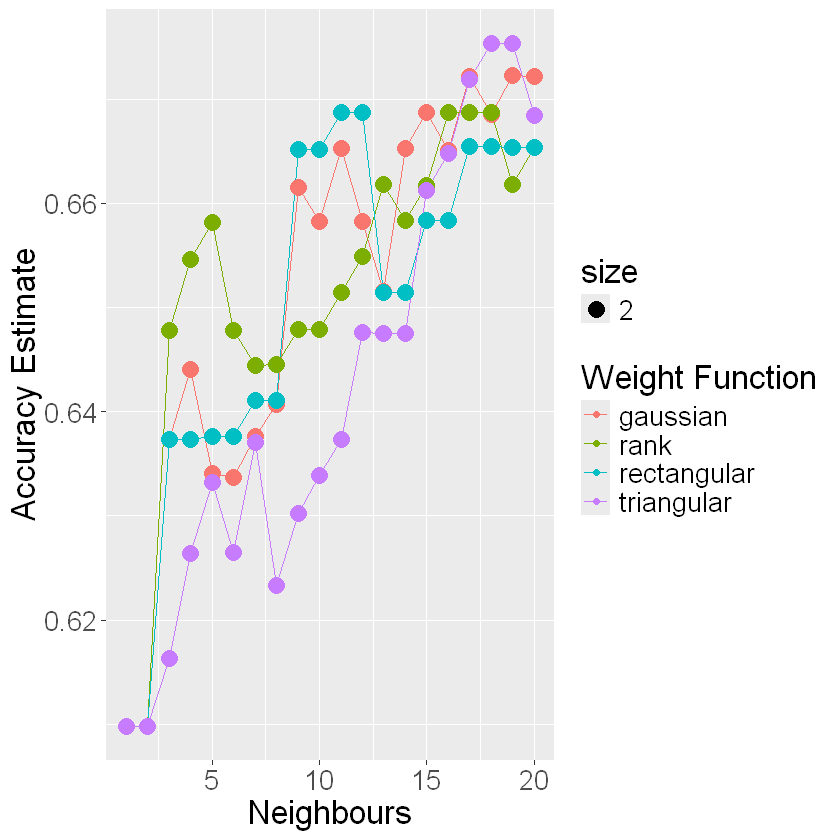

In [40]:
# plot accuracies of all values of k

ggplot(k_model_tuning_accuracies) +
    geom_line(aes(x=neighbors, y=mean, color=weight_func)) +
    geom_point(aes(x=neighbors, y=mean, size=2, color=weight_func)) +
    labs(x = "Neighbours", y = "Accuracy Estimate", color="Weight Function") +
    theme(text = element_text(size=20))

# Print best value of k
best_k <- k_model_tuning_accuracies %>% arrange(desc(mean)) %>% head(1) %>% pull(neighbors)
print("Best k-value:")
print(best_k)
best_k <- k_model_tuning_accuracies %>% arrange(desc(mean)) %>% head(1) %>% pull(mean)

In [41]:
# retrain model on best k-value

# Create model specification
model_spec <- nearest_neighbor(weight_func = "rectangular", neighbors = best_k ) %>%
    set_engine("kknn") %>%
    set_mode("classification")

model <- workflow() %>%
    add_recipe(recipe) %>%
    add_model(model_spec) %>%
    # fit_resamples(resamples = train_vfold) # for v-fold cross validation
    fit(data = train_data) # to train on whole train set with no validation set

model

ERROR: [1m[33mError[39m in `xy_form()`:[22m
[33m![39m `neighbors` must be a whole number or `NULL`, not the number 0.68.


In [ ]:
# Predict on the test set, and create a new DataFrame with inputs and outputs
test_predictions <- model %>% predict(test_data) %>%
    bind_cols(test_data)

In [ ]:
head(test_predictions)

.pred_class,does_it_match,D_M1_M2,D_M1_M3,D_M1_M4,D_M1_M5,D_M1_M6,M1_last_UST,M2_last_UST,M3_last_UST,M4_last_UST,M5_last_UST,M6_last_UST,time_since_M1_last_song,time_since_M2_last_song,time_since_M3_last_song,time_since_M4_last_song,time_since_M5_last_song,time_since_M6_last_song
<fct>,<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,1,94.0368,46.47336,61.21936,62.95599,62.38124,10,9,9,10,8,3,7.059484,6.9407661,5.728446,6.462830,0.7071229,53.565147
0,0,94.0368,46.47336,61.21936,60.45910,62.38124,5,8,8,16,0,0,7.486613,0.9619357,3.114790,2.456056,3.7431272,13.764462
0,0,94.0368,46.47336,61.21936,60.45910,62.38124,9,20,0,0,0,9,7.975315,2.1865670,3.868282,2.100264,-0.3152534,6.236483
0,1,94.0368,46.47336,61.21936,60.45910,62.38124,10,3,9,9,12,0,8.278346,5.3648044,1.648430,2.781516,4.4419531,11.898527
0,0,94.0368,46.47336,61.21936,60.45910,62.38124,9,8,3,0,0,9,9.123102,7.1419217,1.542043,1.665025,0.1875503,7.368994
0,1,94.0368,46.47336,61.21936,60.45910,62.38124,3,13,13,10,10,0,5.408551,0.9534764,6.448776,5.263715,10.0831094,5.117890


In [ ]:
# What was the accuracy, precision, and recall of our model on TEST DATA?
test_predictions %>% metrics(truth = does_it_match, estimate = .pred_class)
test_predictions %>% precision(truth = does_it_match, estimate = .pred_class, event_level = "second") # Precision = correct positive predictions / total positive predictions
test_predictions %>% recall(truth = does_it_match, estimate = .pred_class, event_level = "second") # Recall = correct positive predictions / total positive test set observations

.metric,.estimator,.estimate
<chr>,<chr>,<dbl>
accuracy,binary,0.6746032
kap,binary,0.1329305


.metric,.estimator,.estimate
<chr>,<chr>,<dbl>
precision,binary,0.75


.metric,.estimator,.estimate
<chr>,<chr>,<dbl>
recall,binary,0.1333333


In [ ]:
# test_predictions %>% pull(does_it_match) %>% levels()
confusion_matrix <- test_predictions %>%
    conf_mat(truth = does_it_match, estimate = .pred_class)
confusion_matrix

          Truth
Prediction  0  1
         0 79 39
         1  2  6